In [2]:
# Importing libraries
import math
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

# 1.0 Defining a function in Python

In [3]:
# f is a function
def f(x):
    return 3*x**2 - 4*x + 5

f(3.0)

20.0

Derivative:  14.000003002223593


(20.0, 14.000003002223593)

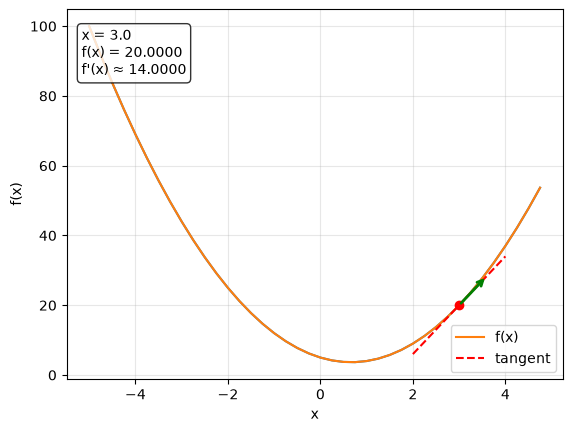

In [4]:
# Plot what this function `f` looks like in matplotlib
xs = np.arange(-5, 5, 0.25)
ys = f(xs)
plt.plot(xs, ys)

# Let's take a derivative of the slope
h = 0.000001
x = 3.0
print( 'Derivative: ', (f(x + h) - f(x))/h )

# adding the f(x) and derivative calculation to the text
from plot_derivative import plot_derivative

# Plot what this function `f` looks like, with the point and derivative direction
xs = np.arange(-5, 5, 0.25)
plot_derivative(f, x=3.0, xs=xs)


# 2.0 Adding a Data Structures to maintain these expressions


In [90]:
class Value:

    def __init__(self, data, _children=(), _op='', label=''):
        self.data = data
        self.grad = 0 # '0' means no effect to the output when changing the variable
        # for holding backprop rules
        self._backward = lambda: None

        # we need to keep pointer to express the computational graphs
        self._prev = set(_children) # child is set for efficiency
        self._op = _op # remember what operation created the current value
        self.label = label


    def __repr__(self):     # define how the print function operates on Value object. Try commenting it out and print Value(); shows <__main__.Value at 0x116b6ec00>
        return f"Value(data={self.data})"
    
    def __add__(self, other): # define what `+` operator does to the Value.data.
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data + other.data, (self, other), '+') # we will return a new value object, and '+' here is the normal add operation.
        
        def _backward():
            self.grad += 1.0 * out.grad
            other.grad += 1.0 * out.grad
        out._backward = _backward

        return out

    def __radd__(self, other):
        return self + other

    def __neg__(self):
        return self * -1

    def __sub__(self, other):
        return self + (-other)

    def __mul__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data * other.data, (self, other), '*')
        
        def _backward():
            self.grad += other.data * out.grad
            other.grad += self.data * out.grad

        out._backward = _backward

        return out

    def __rmul__(self, other): # other * self
        return self * other

    def tanh(self):
        x = self.data
        t = (math.exp(2*x) - 1)/(math.exp(2*x) + 1)
        out = Value(t, (self, ), 'tanh')

        def _backward():
            self.grad += (1 - t**2) * out.grad
        out._backward = _backward

        return out

    def exp(self):
        x = self.data
        out = Value(math.exp(x), (self,), 'exp')

        def _backward():
            self.grad += out.data * out.grad
        out._backward = _backward
        return out

    """Remeber: a/b = a*(1/b) = a*b**-1 | More generally: a*b**k where k is other"""
    def __pow__(self, other):
        assert isinstance(other, (int, float)), "only supporting int/float powers for now"
        out = Value(self.data**other, (self,), f'**{other}')

        def _backward():
            self.grad += other* ( self.data**(other-1) ) * out.grad
        out._backward = _backward
        
        return out

    def __truediv__(self, other):
        return self * other**-1

    def backward(self):
        topo = []
        visited = set()

        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build_topo(child)
                topo.append(v)
        build_topo(self)

        self.grad = 1.0
        for node in reversed(topo):
            node._backward()

In [91]:
a = Value(2.0, label='a')
b = Value(4.0)
a - b

Value(data=-2.0)

In [ ]:
# a = Value(2.0, label='a')
# b = Value(-3.0, label='b')
# c = Value(10.0, label='c')
# e = a*b; e.label = 'e' #""" The direct call for: a*b + c would resemble (   a.__mul__(b)).__add__(c)    )"""
# d = e + c; d.label = 'd'
# print(d) # Try print d._prev and d._op as well.

# # Try ## 2.1 before uncommenting the code
# f = Value(-2.0, label='f')
# L = d*f; L.label = 'L'
# print(L)

## 2.1 Visualize the function graph

In [6]:
from graphviz import Digraph

def trace(root):
    # builds a set of all nodes and edges in a graph
    nodes, edges = set(), set()
    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child, v))
                build(child)
    build(root)
    return nodes, edges

def draw_dot(root):
    dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'}) # LR = left to right

    nodes, edges = trace(root)
    for n in nodes:
        uid = str(id(n))
        # for any value in the graph, create a rectagular ('record') node for it
        dot.node(name = uid, label="{ %s | data %.4f | grad %.4f}" % (n.label, n.data, n.grad), shape='record')
        if n._op:
            # if this value is a result of some operation, create an op node for it
            dot.node(name = uid + n._op, label = n._op)
            # and connect this node to it
            dot.edge(uid + n._op, uid)

    for n1, n2 in edges:
        # connect n1 to the op node of n2
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)

    return dot

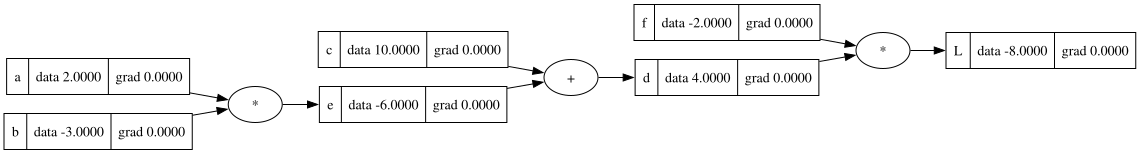

In [38]:
# Draw a graph gradient for L
draw_dot(L)

## 2.2 Computing a gradient

In [8]:
a.grad = (-2.0 * -3.0)
b.grad = (-2.0 * 2.0)


dL / de = -2.0

dL / da = (dL / de) * (de / da)

e = a*b
de / da ? b


In [9]:
def lol():

    h = 0.0001

    # L1
    a = Value(2.0, label='a')
    b = Value(-3.0, label='b')
    c = Value(10.0, label='c')
    e = a*b; e.label = 'e' #""" The direct call for: a*b + c would resemble (   a.__mul__(b)).__add__(c)    )"""
    d = e + c; d.label = 'd'

    # Try ## 2.1 before uncommenting the code
    f = Value(-2.0, label='f')
    L = d*f; L.label = 'L'
    L1 = L.data

    # L2
    a = Value(2.0, label='a') # we bump the value of a here by 'h'
    b = Value(-3.0, label='b')
    b.data += h
    c = Value(10.0, label='c')
    e = a*b; e.label = 'e' #""" The direct call for: a*b + c would resemble (   a.__mul__(b)).__add__(c)    )"""
    d = e + c; d.label = 'd'
    # Try ## 2.1 before uncommenting the code
    f = Value(-2.0, label='f')
    L = d*f; L.label = 'L'
    L2 = L.data

    print((L2 - L1)/ h)

lol()
    

-4.000000000008441


## 3.0 Backpropagation through a `Neuron`

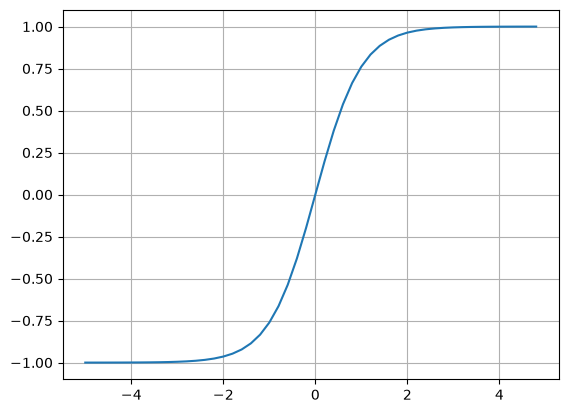

In [10]:
# visualizing a tanh actiavtion function
plt.plot(np.arange(-5, 5, 0.2), np.tanh(np.arange(-5, 5, 0.2))); plt.grid();

In [49]:
# inputs x1, x2
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')
# weights w1, w2
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')
# bias
b = Value(6.8823735870195432, label='b')
# Neuron calculation
x1w1 = x1*w1; x1w1.label = 'x1*w1'
x2w2 = x2*w2; x2w2.label = 'x2*w2'
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1*w1 + x2*w2'
n = x1w1x2w2 + b; n.label = 'n'
o = n.tanh(); o.label = 'o'

#draw_dot(o)

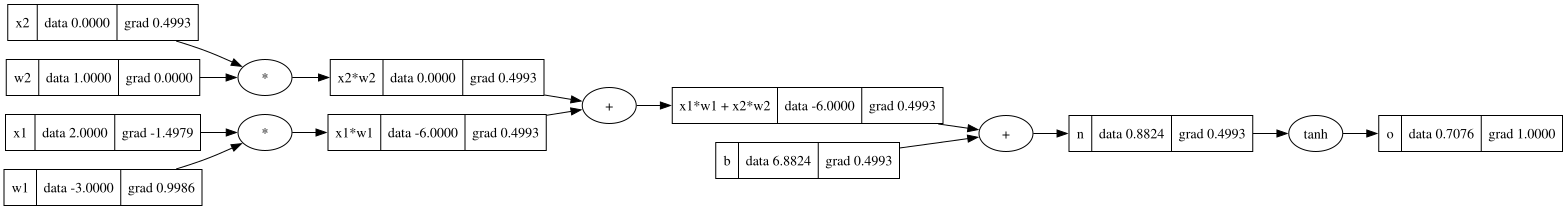

In [52]:
draw_dot(o)

In [ ]:
# We need to add a function to update the gradient on backward pass
# we then backward through the expression; need to calculate the backward's full dependencies
o.grad = 1.0
# o._backward()
# n._backward()
# b._backward()
# x1w1x2w2._backward()
# x2w2._backward()
# x1w1._backward()


In [ ]:
# Forward pass
x1.grad = w1.data * x1w1.grad
w1.grad = x1.data * x1w1.grad

In [22]:
x2.grad = w2.data * x2w2.grad
w2.grad = x2.data * x2w2.grad

In [20]:
x1w1.grad = 0.5
x2w2.grad = 0.5

In [19]:
x1w1x2w2.grad = 0.5
b.grad = 0.5

In [ ]:
o.grad = 1.0 # derivative of o with respect to o

In [18]:
n.grad = 0.5

In [17]:
1 - o.data**2

0.4992931434542238

In [ ]:
# o = tanh(n)
# do/dn = 1 - tanh(n)**2 = 1 - o**2

## 3.1 Doing Backward Pass Automatically

In [ ]:
# this build the topological graph
topo = []
visited = set()

def build_topo(v):
    if v not in visited:
        visited.add(v)
        for child in v._prev:
            build_topo(child)
        topo.append(v)
build_topo(o)
topo

## 3.2 Automated backprop

In [94]:
# inputs x1, x2
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')
# weights w1, w2
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')
# bias
b = Value(6.8823735870195432, label='b')
# Neuron calculation
x1w1 = x1*w1; x1w1.label = 'x1*w1'
x2w2 = x2*w2; x2w2.label = 'x2*w2'
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1*w1 + x2*w2'
n = x1w1x2w2 + b; n.label = 'n'
o = n.tanh(); o.label = 'o'
o.backward()

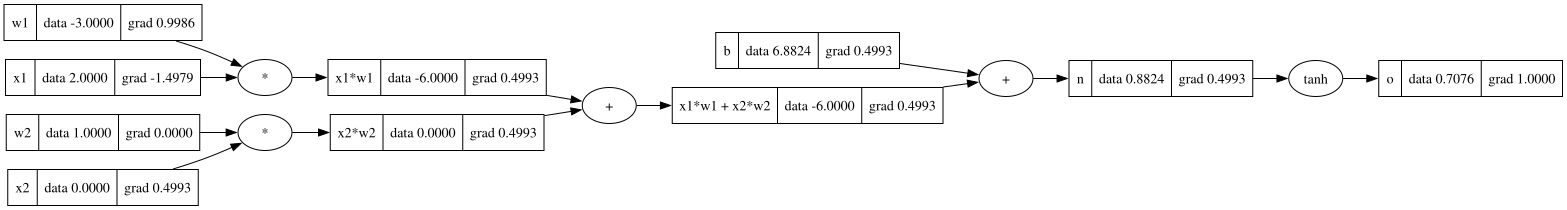

In [95]:
draw_dot(o)

In [59]:
o.backward()

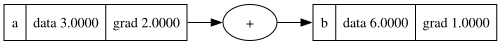

In [63]:
a = Value(3.0, label='a')
b = a + a; b.label='b'
b.backward()
draw_dot(b)

## 3.3 Adding new calculation of tanh

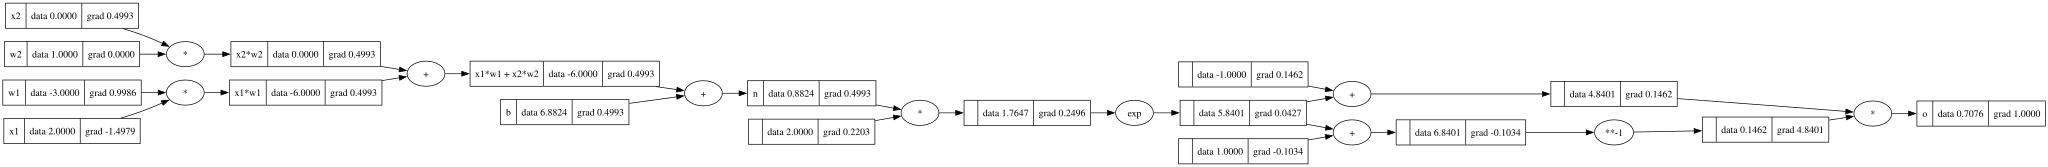

In [96]:
# inputs x1, x2
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')
# weights w1, w2
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')
# bias
b = Value(6.8823735870195432, label='b')
# Neuron calculation
x1w1 = x1*w1; x1w1.label = 'x1*w1'
x2w2 = x2*w2; x2w2.label = 'x2*w2'
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1*w1 + x2*w2'
n = x1w1x2w2 + b; n.label = 'n'
# ---
e = (2*n).exp()
o = (e - 1) / (e + 1)
# ---
o.label = 'o'
o.backward()
draw_dot(o)

# 4. Implementing the same neiron on pytorch

In [99]:
import torch

x1 = torch.Tensor([2.0]).double()               ; x1.requires_grad = True
x2 = torch.Tensor([0.0]).double()               ; x2.requires_grad = True
w1 = torch.Tensor([-3.0]).double()              ; w1.requires_grad = True
w2 = torch.Tensor([1.0]).double()               ; w2.requires_grad = True
b = torch.Tensor([6.8813735870195432]).double() ; b.requires_grad = True
n = x1*w1 + x2*w2 + b
o = torch.tanh(n)

print(o.data.item())
o.backward()

print('---')
print('x2', x2.grad.item())
print('w2', x2.grad.item())
print('x1', x2.grad.item())
print('w1', x2.grad.item())

0.7071066904050358
---
x2 0.5000001283844369
w2 0.5000001283844369
x1 0.5000001283844369
w1 0.5000001283844369


## 4.1 Implementing a pytorch neuron

In [124]:
import random

class Neuron:

    def __init__(self, nin) -> None:
        self.w = [Value(random.uniform(-1, 1)) for _ in range(nin)]
        self.b = Value(random.uniform(-1, 1))

    def __call__(self, x):
        # w * x + b
        act = sum((wi*xi for wi, xi in zip(self.w, x)), self.b)
        out = act.tanh()
        return out


class Layer:

    def __init__(self, nin, nout):
        self.neurons = [Neuron(nin) for _ in range(nout)]

    def __call__(self, x):
        outs = [n(x) for n in self.neurons]
        return outs[0] if len(outs) == 1 else outs


class MLP:

    def __init__(self, nin, nouts):
        sz = [nin] + nouts
        self.layers = [Layer(sz[i], sz[i+1]) for i in range(len(nouts))]

    def __call__(self, x):
        for layer in self.layers:
            x = layer(x)
        return x
        
x = [2.0, 3.0, -1.0]
n = MLP(2, [4, 4, 1])
n(x)

Value(data=-0.3448160724370464)

In [126]:
random.uniform(-1, 1)

-0.9811477858408264

In [ ]:
class Neuron:

    def __init__(self, nin) -> None:
        self.w = [Value(random.uniform(-1,1)) for _ in range(nin)]
        self.b = Value(random.uniform(-1,1))

    def __call__(self, x):
        act = sum(([wi*xi for xi, wi in zip(self.w, x)]), self.b)
        out = act.tanh()
        return out

class Layer:

    def __init__(self, nin, nout):
        """nin is the # of data inputs; nout is the number of neurons."""
        self.neurons = [Neuron(nin) for _ in range(nout)]

    # Each of the neurons in a Layer should produce activation when an input in entered
    def __call__(self, x):
        outs = [n(x) for n in self.neurons]
        return outs

In [141]:
x = [1, 2, 3, 4]
a = Neuron(len(x))
a(x)

Value(data=0.9998008505103051)

In [142]:
x = [1, 2, 3, 4]
a = Layer(2, 3)
a(x)

[Value(data=0.6913193168747661),
 Value(data=0.9539792147873563),
 Value(data=-0.41548281596593417)]